# Cox-CC

In this notebook we will train the [Cox-CC method](http://jmlr.org/papers/volume20/18-424/18-424.pdf).
We will use the METABRIC data sets as an example

A more detailed introduction to the `pycox` package can be found in [this notebook](https://nbviewer.jupyter.org/github/havakv/pycox/blob/master/examples/01_introduction.ipynb) about the `LogisticHazard` method.

The main benefit Cox-CC (and the other Cox methods) has over Logistic-Hazard is that it is a continuous-time method, meaning we do not need to discretize the time scale.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from pycox.preprocessing.feature_transforms import OrderedCategoricalLong
from sklearn_pandas import DataFrameMapper

import torch
import torchtuples as tt

from pycox.datasets import metabric, support
from pycox.models import CoxCC
from pycox.evaluation import EvalSurv

In [2]:
## Uncomment to install `sklearn-pandas`
# ! pip install sklearn-pandas

In [3]:
np.random.seed(1234)
_ = torch.manual_seed(123)

## Dataset

We load the METABRIC data set and split in train, test and validation.

In [13]:
df_train = support.read_df()
# df_test = df_train.sample(frac=0.2)
# df_train = df_train.drop(df_test.index)
df_val = df_train.sample(frac=0.2)
df_train = df_train.drop(df_val.index)

In [14]:
df_train.head()

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,x11,x12,x13,duration,event
0,82.709961,1.0,2.0,1.0,0.0,0.0,0.0,160.0,55.0,16.0,38.195309,142.0,19.000000,1.099854,30.0,1
1,79.660950,1.0,0.0,1.0,0.0,0.0,1.0,54.0,67.0,16.0,38.000000,142.0,10.000000,0.899902,1527.0,0
2,23.399990,1.0,2.0,3.0,0.0,0.0,1.0,87.0,144.0,45.0,37.296879,130.0,5.199219,1.199951,96.0,1
3,53.075989,1.0,4.0,3.0,0.0,0.0,0.0,55.0,100.0,18.0,36.000000,135.0,8.699219,0.799927,892.0,0
9,67.462952,1.0,4.0,1.0,0.0,0.0,1.0,73.0,75.0,28.0,36.000000,140.0,15.798828,0.699951,70.0,1


## Feature transforms
We have 9 covariates, in addition to the durations and event indicators.

We will standardize the 5 numerical covariates, and leave the binary variables as is. As variables needs to be of type `'float32'`, as this is required by pytorch.

In [15]:
cols_standardize =  ['x0', 'x7', 'x8', 'x9', 'x10', 'x11', 'x12', 'x13']
cols_leave = ['x1', 'x4', 'x5']
cols_categorical =  ['x2', 'x3', 'x6']

standardize = [([col], StandardScaler()) for col in cols_standardize]
leave = [(col, None) for col in cols_leave]
categorical = [(col, OrderedCategoricalLong()) for col in cols_categorical]

x_mapper_float = DataFrameMapper(standardize + leave)
x_mapper_long = DataFrameMapper(categorical)  # we need a separate mapper to ensure the data type 'int64'

In [23]:
x_fit_transform = lambda df: np.concatenate([x_mapper_float.fit_transform(df), x_mapper_long.fit_transform(df)], axis=-1)
x_transform = lambda df: np.concatenate([x_mapper_float.transform(df), x_mapper_long.transform(df)], axis=-1)

We need no label transforms

In [51]:
x_train = x_fit_transform(df_train).astype(np.float32)
x_val = x_transform(df_val).astype(np.float32)
# x_test = x_transform(df_test)

get_target = lambda df: (df['duration'].values, df['event'].values)
y_train = get_target(df_train)
y_val = get_target(df_val)
durations_val, events_val = get_target(df_val)
val = tt.tuplefy(x_val, y_val)

In [25]:
val.shapes()

((1775, 14), ((1775,), (1775,)))

With `TupleTree` (the results of `tt.tuplefy`) we can easily repeat the validation dataset multiple times. This will be useful for reduce the variance of the validation loss, as the validation loss of `CoxCC` is not deterministic.

In [20]:
val.repeat(2).cat().shapes()

(((3550, 11), (3550, 3)), ((3550,), (3550,)))

## Neural net

We create a simple MLP with two hidden layers, ReLU activations, batch norm and dropout. 
Here, we just use the `torchtuples.practical.MLPVanilla` net to do this.

Note that we set `out_features` to 1, and that we have not `output_bias`.

In [78]:
in_features = x_train.shape[1]
num_nodes = []
out_features = 1
batch_norm = True
dropout = 0.1
output_bias = False

net = tt.practical.MLPVanilla(in_features, num_nodes, out_features, batch_norm,
                              dropout, output_bias=output_bias)

## Training the model

To train the model we need to define an optimizer. You can choose any `torch.optim` optimizer, but here we instead use one from `tt.optim` as it has some added functionality.
We use the `Adam` optimizer, but instead of choosing a learning rate, we will use the scheme proposed by [Smith 2017](https://arxiv.org/pdf/1506.01186.pdf) to find a suitable learning rate with `model.lr_finder`. See [this post](https://towardsdatascience.com/finding-good-learning-rate-and-the-one-cycle-policy-7159fe1db5d6) for an explanation.

In [79]:
model = CoxCC(net, tt.optim.Adam)

/home/peijie.qiu/anaconda3/envs/pytorch/lib/python3.8/site-packages/pycox/models/data.py:38: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  for ix, t in keys.iteritems():


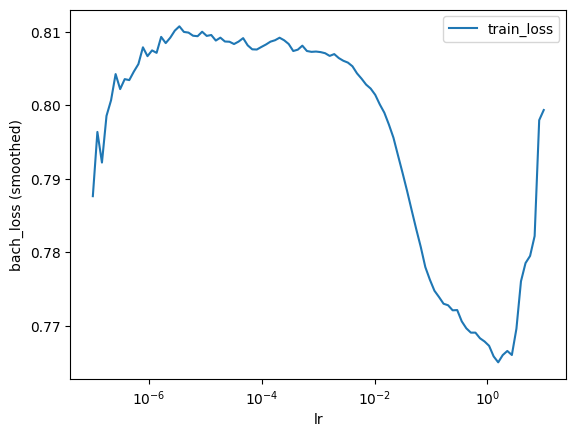

In [80]:
batch_size = 1024
lrfinder = model.lr_finder(x_train, y_train, batch_size, tolerance=2)
_ = lrfinder.plot()

In [32]:
# lrfinder.get_best_lr()

Often, this learning rate is a little high, so we instead set it manually to 0.01

In [81]:
model.optimizer.set_lr(0.01)

We include the `EarlyStopping` callback to stop training when the validation loss stops improving. After training, this callback will also load the best performing model in terms of validation loss.

In [82]:
epochs = 512
callbacks = [tt.callbacks.EarlyStopping()]
verbose = True

In [83]:
%%time
log = model.fit(x_train, y_train, batch_size, epochs, callbacks, verbose,
                val_data=val.repeat(10).cat())

/home/peijie.qiu/anaconda3/envs/pytorch/lib/python3.8/site-packages/pycox/models/data.py:38: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  for ix, t in keys.iteritems():


0:	[0s / 0s],		train_loss: 0.7933,	val_loss: 0.7658
1:	[0s / 0s],		train_loss: 0.7501,	val_loss: 0.7264
2:	[0s / 0s],		train_loss: 0.7183,	val_loss: 0.7034
3:	[0s / 0s],		train_loss: 0.6993,	val_loss: 0.6886
4:	[0s / 0s],		train_loss: 0.6879,	val_loss: 0.6818
5:	[0s / 0s],		train_loss: 0.6849,	val_loss: 0.6792
6:	[0s / 0s],		train_loss: 0.6781,	val_loss: 0.6747
7:	[0s / 0s],		train_loss: 0.6795,	val_loss: 0.6731
8:	[0s / 0s],		train_loss: 0.6760,	val_loss: 0.6737
9:	[0s / 0s],		train_loss: 0.6755,	val_loss: 0.6713
10:	[0s / 0s],		train_loss: 0.6775,	val_loss: 0.6743
11:	[0s / 0s],		train_loss: 0.6740,	val_loss: 0.6719
12:	[0s / 0s],		train_loss: 0.6730,	val_loss: 0.6698
13:	[0s / 0s],		train_loss: 0.6732,	val_loss: 0.6725
14:	[0s / 0s],		train_loss: 0.6791,	val_loss: 0.6696
15:	[0s / 0s],		train_loss: 0.6726,	val_loss: 0.6714
16:	[0s / 0s],		train_loss: 0.6723,	val_loss: 0.6716
17:	[0s / 1s],		train_loss: 0.6721,	val_loss: 0.6708
18:	[0s / 1s],		train_loss: 0.6748,	val_loss: 0.6728
19:

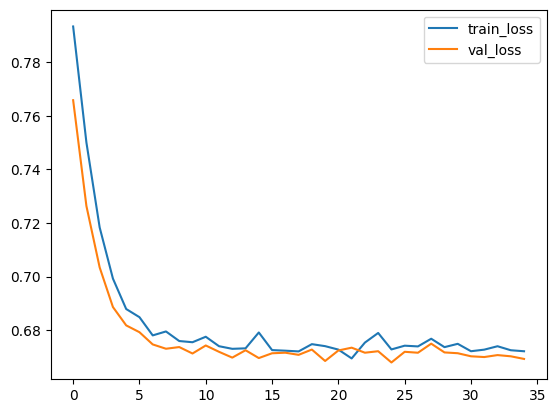

In [84]:
_ = log.plot()

We can get the partial log-likelihood

In [73]:
model.partial_log_likelihood(*val).mean()

-6.8707857

## Prediction

For evaluation we first need to obtain survival estimates for the test set.
This can be done with `model.predict_surv` which returns an array of survival estimates, or with `model.predict_surv_df` which returns the survival estimates as a dataframe.

However, as `CoxCC` is semi-parametric, we first need to get the non-parametric baseline hazard estimates with `compute_baseline_hazards`. 

Note that for large datasets the `sample` argument can be used to estimate the baseline hazard on a subset.

In [86]:
_ = model.compute_baseline_hazards()

In [87]:
surv = model.predict_surv_df(x_val)

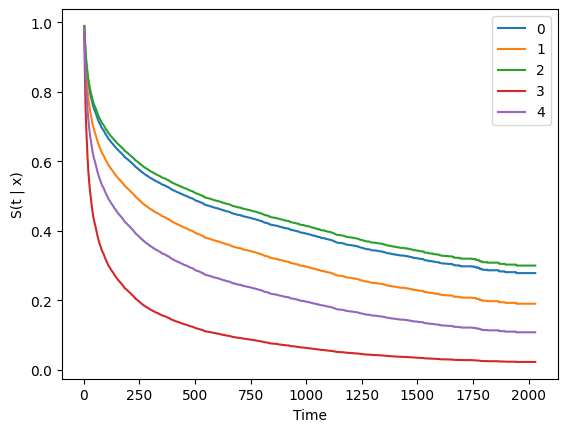

In [64]:
surv.iloc[:, :5].plot()
plt.ylabel('S(t | x)')
_ = plt.xlabel('Time')

## Evaluation

We can use the `EvalSurv` class for evaluation the concordance, brier score and binomial log-likelihood. Setting `censor_surv='km'` means that we estimate the censoring distribution by Kaplan-Meier on the test set.

In [88]:
ev = EvalSurv(surv, durations_val, events_val, censor_surv='km')

/home/peijie.qiu/anaconda3/envs/pytorch/lib/python3.8/site-packages/pycox/evaluation/eval_surv.py:36: FutureWarning: is_monotonic is deprecated and will be removed in a future version. Use is_monotonic_increasing instead.
  assert pd.Series(self.index_surv).is_monotonic


In [89]:
ev.concordance_td()

0.5677058014372425